# Modul 5 — Statistical Process Control (SPC) yang Lebih Tajam
SPC menjawab: *apakah proses sedang stabil, atau ada sebab khusus yang perlu ditindak?* Kita bangun empat alat dari nol:
bagan **I-MR** (Shewhart), **aturan Western Electric**, **EWMA** dan **CUSUM** (peka pada pergeseran kecil), lalu **kapabilitas proses** (Cp, Cpk).

Dua variabel: **energi per ton katoda** (makin kecil makin baik) dan **recovery** (makin besar makin baik).

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
h = pd.read_excel(XLSX, sheet_name="Data_Harian")
h["Tanggal"] = pd.to_datetime(h["Tanggal"]); h = h.sort_values("Tanggal").reset_index(drop=True)
h["Downtime"] = h.Jam_Downtime > 0

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


## 1. Fase I dan Fase II
- **Fase I:** pilih periode yang dianggap representatif, hitung batas kendali darinya. Kita pakai **Januari–Juni** (181 hari).
- **Fase II:** pantau data baru (**Juli–September**) terhadap batas yang sudah dibekukan.

Batas dihitung dari data Fase I saja. Menghitung batas dari seluruh data membuat sinyal tersamar oleh data yang sedang diuji.

In [ ]:
BASE_END = pd.Timestamp("2026-06-30")
faseI = h.Tanggal <= BASE_END
print("Fase I :", faseI.sum(), "hari | Fase II:", (~faseI).sum(), "hari")

Fase I : 181 hari | Fase II: 92 hari


## 2. Bagan I-MR (Individuals & Moving Range)
Data kita satu nilai per hari, bukan sub-grup, jadi dipakai bagan individual.
- Simpangan baku **dalam-proses** diestimasi dari rentang bergerak: **σ = MR̄ / 1,128**.
- Batas: **CL ± 3σ**. Batas atas bagan MR = **3,267 · MR̄**.

Mengapa bukan simpangan baku biasa? Simpangan baku biasa ikut membesar oleh pergeseran dan tren, sehingga *menyembunyikan* sinyal.

In [ ]:
def imr_params(x):
    x = np.asarray(x, float); mr = np.abs(np.diff(x))
    mrbar = mr.mean(); sigma = mrbar / 1.128
    return dict(cl=x.mean(), sigma=sigma, mrbar=mrbar, ucl=x.mean()+3*sigma, lcl=x.mean()-3*sigma, mr_ucl=3.267*mrbar)

def western_electric(x, cl, sigma):
    """Mengembalikan DataFrame boolean: aturan 1-4 per titik (True = melanggar)."""
    z = (np.asarray(x, float) - cl) / sigma; n = len(z); r = np.zeros((n, 4), bool)
    r[:, 0] = np.abs(z) > 3
    for i in range(2, n):                                  # 2 dari 3 titik melewati 2σ di sisi sama
        w = z[i-2:i+1]
        if (w > 2).sum() >= 2 or (w < -2).sum() >= 2: r[i, 1] = True
    for i in range(4, n):                                  # 4 dari 5 titik melewati 1σ di sisi sama
        w = z[i-4:i+1]
        if (w > 1).sum() >= 4 or (w < -1).sum() >= 4: r[i, 2] = True
    for i in range(7, n):                                  # 8 titik berturut-turut di satu sisi
        w = z[i-7:i+1]
        if (w > 0).all() or (w < 0).all(): r[i, 3] = True
    return pd.DataFrame(r, columns=["R1_3sigma", "R2_2dari3", "R3_4dari5", "R4_8berturut"])

x = h.Energi_per_t_Katoda_MWh
P = imr_params(x[faseI])
print({k: round(v, 4) for k, v in P.items()})
print(f"σ dari MR̄ = {P['sigma']:.4f}  vs  simpangan baku biasa Fase I = {x[faseI].std():.4f}")
we = western_electric(x, P["cl"], P["sigma"])
we["Fase"] = np.where(faseI, "I", "II"); we["Downtime"] = h.Downtime
we["sinyal_apa_saja"] = we[["R1_3sigma", "R2_2dari3", "R3_4dari5", "R4_8berturut"]].any(axis=1)
print("\nJumlah titik melanggar tiap aturan:"); print(we.groupby("Fase")[["R1_3sigma", "R2_2dari3", "R3_4dari5", "R4_8berturut", "sinyal_apa_saja"]].sum())
r1 = we.R1_3sigma
print(f"\nSinyal aturan 1 (di luar 3σ): {r1.sum()} titik; {h.Downtime[r1].sum()} di antaranya jatuh pada hari downtime")

{'cl': np.float64(1.4717), 'sigma': np.float64(0.0609), 'mrbar': np.float64(0.0687), 'ucl': np.float64(1.6545), 'lcl': np.float64(1.2889), 'mr_ucl': np.float64(0.2245)}
σ dari MR̄ = 0.0609  vs  simpangan baku biasa Fase I = 0.0701

Jumlah titik melanggar tiap aturan:
      R1_3sigma  R2_2dari3  R3_4dari5  R4_8berturut  sinyal_apa_saja
Fase                                                                
I             4          5          9             0               11
II            0          0          3             0                3

Sinyal aturan 1 (di luar 3σ): 4 titik; 4 di antaranya jatuh pada hari downtime


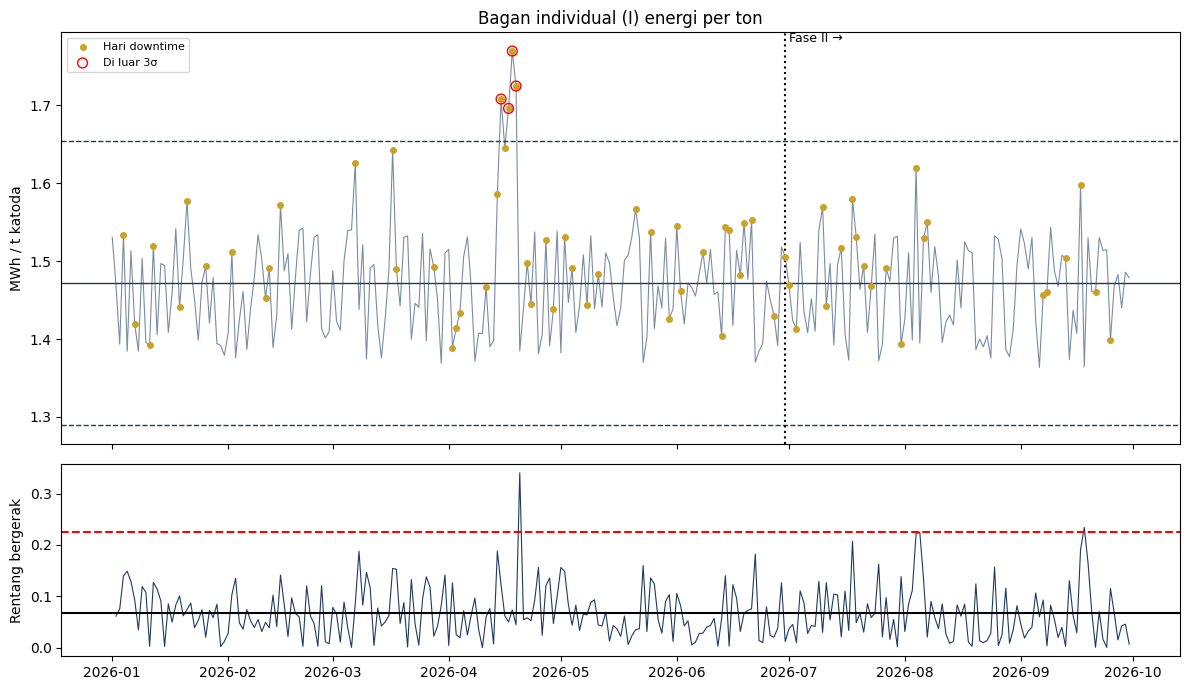

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
ax[0].plot(h.Tanggal, x, "-", color="#7A8CA3", lw=.8)
ax[0].scatter(h.Tanggal[h.Downtime], x[h.Downtime], s=16, color="#C9A227", zorder=3, label="Hari downtime")
ax[0].scatter(h.Tanggal[r1], x[r1], s=50, facecolor="none", edgecolor="red", zorder=4, label="Di luar 3σ")
for v, ls in [(P["cl"], "-"), (P["ucl"], "--"), (P["lcl"], "--")]: ax[0].axhline(v, color="#1F3A5F", ls=ls, lw=1)
ax[0].axvline(BASE_END, color="k", ls=":"); ax[0].text(BASE_END, ax[0].get_ylim()[1], " Fase II →", va="top", fontsize=9)
ax[0].set_ylabel("MWh / t katoda"); ax[0].set_title("Bagan individual (I) energi per ton"); ax[0].legend(loc="upper left", fontsize=8)
mr = np.r_[np.nan, np.abs(np.diff(x))]
ax[1].plot(h.Tanggal, mr, color="#1F3A5F", lw=.8); ax[1].axhline(P["mrbar"], color="k"); ax[1].axhline(P["mr_ucl"], color="r", ls="--")
ax[1].set_ylabel("Rentang bergerak"); plt.tight_layout(); plt.show()

**Cara membaca:** titik emas = hari downtime. Jika sinyal di luar 3σ hampir semuanya emas, penyebab khususnya sudah dikenal (pemanasan ulang setelah berhenti), bukan masalah baru yang misterius.

## 3. EWMA — peka pada pergeseran kecil yang menetap
`z_t = λ·x_t + (1−λ)·z_{t−1}`, λ = 0,2. Batas: `CL ± L·σ·√(λ/(2−λ)·(1−(1−λ)^{2t}))` dengan L = 3. EWMA "mengingat" beberapa hari terakhir, sehingga pergeseran kecil (≈ 0,5–1σ) yang lolos dari bagan Shewhart akan terdeteksi.

In [ ]:
def ewma(x, cl, sigma, lam=0.2, L=3.0):
    z = np.zeros(len(x)); prev = cl
    for i, v in enumerate(x): prev = lam * v + (1 - lam) * prev; z[i] = prev
    t = np.arange(1, len(x) + 1)
    w = L * sigma * np.sqrt(lam / (2 - lam) * (1 - (1 - lam) ** (2 * t)))
    return z, cl + w, cl - w

ze, uE, lE = ewma(x.values, P["cl"], P["sigma"])
oocE = (ze > uE) | (ze < lE)
print(f"EWMA: {oocE.sum()} sinyal (Fase I: {oocE[faseI.values].sum()}, Fase II: {oocE[~faseI.values].sum()})")
first = h.Tanggal[oocE & ~faseI.values]
print("Sinyal EWMA pertama di Fase II:", first.iloc[0].date() if len(first) else "tidak ada")

EWMA: 7 sinyal (Fase I: 7, Fase II: 0)
Sinyal EWMA pertama di Fase II: tidak ada


## 4. CUSUM — mengakumulasi penyimpangan
`C⁺_t = max(0, C⁺_{t−1} + (x_t − μ₀ − kσ))`, `C⁻_t = max(0, C⁻_{t−1} + (μ₀ − kσ − x_t))`. Dengan **k = 0,5** (peka terhadap pergeseran 1σ) dan batas keputusan **h = 5σ**. Sinyal muncul ketika akumulasi melewati h.

CUSUM: 20 titik di atas batas (Fase II: 0)
Sinyal CUSUM atas pertama di Fase II: tidak ada


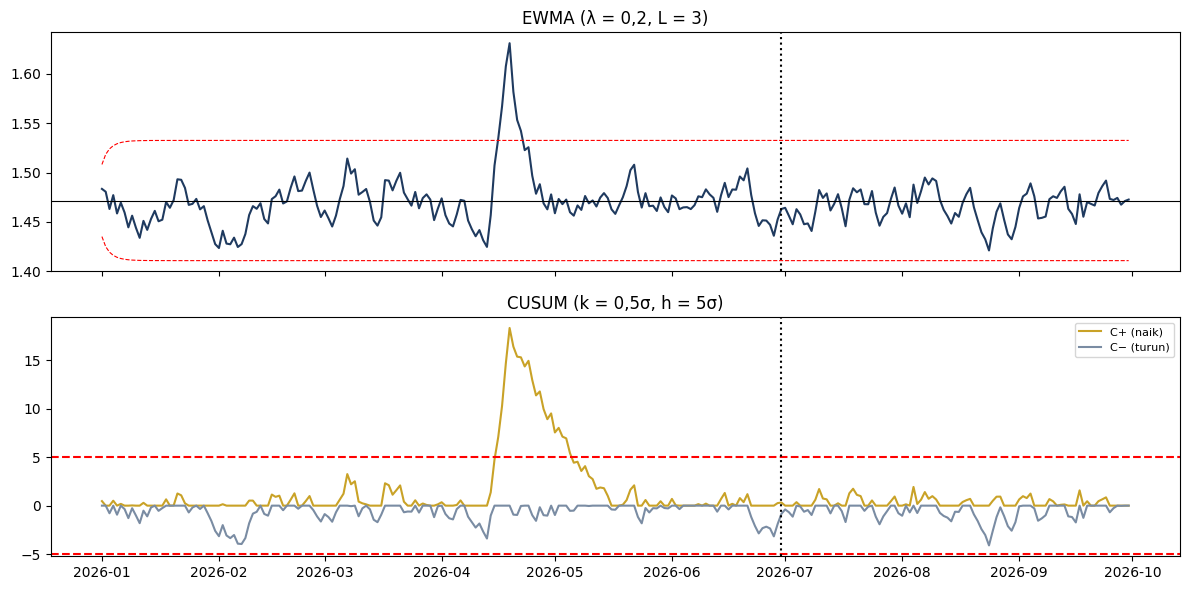

In [ ]:
def cusum(x, mu, sigma, k=0.5, h_=5.0):
    cp = np.zeros(len(x)); cm = np.zeros(len(x)); a = b = 0
    for i, v in enumerate(x):
        a = max(0, a + (v - mu) / sigma - k); b = max(0, b + (mu - v) / sigma - k); cp[i], cm[i] = a, b
    return cp, cm, h_
cp, cm, hh = cusum(x.values, P["cl"], P["sigma"])
sig_c = (cp > hh) | (cm > hh)
print(f"CUSUM: {sig_c.sum()} titik di atas batas (Fase II: {sig_c[~faseI.values].sum()})")
first_c = h.Tanggal[(cp > hh) & ~faseI.values]
print("Sinyal CUSUM atas pertama di Fase II:", first_c.iloc[0].date() if len(first_c) else "tidak ada")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(h.Tanggal, ze, color="#1F3A5F"); ax[0].plot(h.Tanggal, uE, "r--", lw=.8); ax[0].plot(h.Tanggal, lE, "r--", lw=.8)
ax[0].axhline(P["cl"], color="k", lw=.8); ax[0].set_title("EWMA (λ = 0,2, L = 3)"); ax[0].axvline(BASE_END, color="k", ls=":")
ax[1].plot(h.Tanggal, cp, label="C+ (naik)", color="#C9A227"); ax[1].plot(h.Tanggal, -cm, label="C− (turun)", color="#7A8CA3")
ax[1].axhline(hh, color="r", ls="--"); ax[1].axhline(-hh, color="r", ls="--"); ax[1].legend(fontsize=8); ax[1].set_title("CUSUM (k = 0,5σ, h = 5σ)"); ax[1].axvline(BASE_END, color="k", ls=":")
plt.tight_layout(); plt.show()

## 5. Perbandingan kepekaan: bagan mana yang paling cepat mendeteksi pergeseran?
Kita **menyuntikkan** pergeseran buatan +0,5σ, +1σ, +2σ pada data Fase II dan menghitung berapa hari sampai tiap bagan memberi sinyal pertama (rata-rata run length, ARL). Dengan 1.000 simulasi.

In [ ]:
rng = np.random.default_rng(11)
def run_length(shift_sigma, chart, n=300, reps=1000):
    out = []
    for _ in range(reps):
        d = rng.normal(P["cl"], P["sigma"], n); d[50:] += shift_sigma * P["sigma"]           # pergeseran mulai hari ke-50
        if chart == "Shewhart 3σ": s = np.abs(d - P["cl"]) > 3 * P["sigma"]
        elif chart == "EWMA": z, u, l = ewma(d, P["cl"], P["sigma"]); s = (z > u) | (z < l)
        else: a, b, hv = cusum(d, P["cl"], P["sigma"]); s = (a > hv) | (b > hv)
        idx = np.where(s[50:])[0]; out.append(idx[0] + 1 if len(idx) else np.nan)
    return np.nanmean(out), np.isnan(out).mean()
tab = pd.DataFrame({c: {f"+{s}σ": run_length(s, c)[0] for s in [0.5, 1.0, 2.0]} for c in ["Shewhart 3σ", "EWMA", "CUSUM"]})
print("Rata-rata hari sampai sinyal pertama setelah pergeseran (makin kecil makin baik):"); print(tab.round(1))

Rata-rata hari sampai sinyal pertama setelah pergeseran (makin kecil makin baik):
       Shewhart 3σ  EWMA  CUSUM
+0.5σ         96.4  41.5   35.3
+1.0σ         40.6  10.5    9.7
+2.0σ          6.3   3.8    3.6


**Pelajaran:** bagan Shewhart bagus untuk lonjakan besar (≥ 2σ), tetapi lambat untuk pergeseran kecil. EWMA dan CUSUM jauh lebih cepat pada pergeseran 0,5–1σ. Industri biasanya memakai Shewhart **bersama** EWMA atau CUSUM.

## 6. Recovery: kasus data berekor panjang
Recovery punya 5 hari anjlok ke 90–92%. Bagan I-MR akan menandainya sebagai sinyal, tetapi simpangan baku dari MR̄ juga ikut terpengaruh oleh lompatan besar.

In [ ]:
y = h.Recovery_Persen
Py = imr_params(y[faseI])
wy = western_electric(y, Py["cl"], Py["sigma"])
print({k: round(v, 3) for k, v in Py.items()})
print("Titik di bawah LCL (3σ):", (y < Py["lcl"]).sum(), "-> tanggal:", [d.date().isoformat() for d in h.Tanggal[y < Py["lcl"]]])
# Pembanding yang tahan pencilan: median dan MAD
med = y[faseI].median(); mad = 1.4826 * np.median(np.abs(y[faseI] - med))
print(f"Estimasi tahan-pencilan: median={med:.3f}, σ(MAD)={mad:.3f}  vs  σ(MR̄)={Py['sigma']:.3f}")
print("Titik di bawah median − 3·σ(MAD):", (y < med - 3 * mad).sum())

{'cl': np.float64(98.088), 'sigma': np.float64(0.689), 'mrbar': np.float64(0.777), 'ucl': np.float64(100.155), 'lcl': np.float64(96.021), 'mr_ucl': np.float64(2.54)}
Titik di bawah LCL (3σ): 5 -> tanggal: ['2026-01-08', '2026-03-05', '2026-03-28', '2026-06-05', '2026-09-09']
Estimasi tahan-pencilan: median=98.246, σ(MAD)=0.461  vs  σ(MR̄)=0.689
Titik di bawah median − 3·σ(MAD): 5


## 7. Kapabilitas proses (Cp, Cpk)
Kapabilitas membandingkan **suara proses** dengan **batas spesifikasi** (permintaan pelanggan). Rumus: `Cp = (USL − LSL)/(6σ)`, `Cpk = min(USL − μ, μ − LSL)/(3σ)`. Cpk ≥ 1,33 dianggap mampu.

**Penting:** batas spesifikasi di bawah adalah **angka contoh** untuk latihan (USL energi/t = 1,60 MWh/t, LSL recovery = 97%); bukan spesifikasi sebenarnya.

In [ ]:
def capability(x, lsl=None, usl=None):
    mu, s = np.mean(x), imr_params(x)["sigma"]
    cp_ = (usl - lsl) / (6 * s) if (usl is not None and lsl is not None) else np.nan
    cpu = (usl - mu) / (3 * s) if usl is not None else np.inf
    cpl = (mu - lsl) / (3 * s) if lsl is not None else np.inf
    return dict(mean=mu, sigma_within=s, sigma_overall=np.std(x, ddof=1), Cp=cp_, Cpk=min(cpu, cpl))
for nama, v, kw in [("Energi/t (USL=1,60)", x, dict(usl=1.60)), ("Recovery (LSL=97)", y, dict(lsl=97.0))]:
    for lbl, m in [("Fase I", faseI), ("Fase II", ~faseI)]:
        c = capability(v[m].values, **kw); print(f"{nama:22s} {lbl:8s} mean={c['mean']:.3f}  σ_dalam={c['sigma_within']:.4f}  σ_total={c['sigma_overall']:.4f}  Cpk={c['Cpk']:.2f}")
# Persentase di luar spesifikasi (empiris):
print(f"\nHari energi/t > 1,60: {(x > 1.60).sum()} ({(x > 1.60).mean()*100:.1f}%) | hari recovery < 97%: {(y < 97).sum()} ({(y < 97).mean()*100:.1f}%)")

Energi/t (USL=1,60)    Fase I   mean=1.472  σ_dalam=0.0609  σ_total=0.0701  Cpk=0.70
Energi/t (USL=1,60)    Fase II  mean=1.466  σ_dalam=0.0587  σ_total=0.0603  Cpk=0.76
Recovery (LSL=97)      Fase I   mean=98.088  σ_dalam=0.6891  σ_total=1.2121  Cpk=0.53
Recovery (LSL=97)      Fase II  mean=98.267  σ_dalam=0.5421  σ_total=0.7524  Cpk=0.78

Hari energi/t > 1,60: 8 (2.9%) | hari recovery < 97%: 5 (1.8%)


**Kesimpulan modul 5.**
*   Energi per ton stabil. Pada Fase II tidak ada sinyal di luar 3σ, EWMA, maupun CUSUM. Dari 4 titik di luar 3σ pada Fase I, semuanya jatuh pada hari downtime.
*   Simulasi ARL menunjukkan EWMA dan CUSUM mendeteksi pergeseran kecil sekitar 2,5 kali lebih cepat dari Shewhart (+0,5σ: 35–42 hari vs 96 hari).
*   Cpk energi 0,70–0,76 dan recovery 0,53–0,78 terhadap batas spesifikasi contoh. Batas ini asumsi, jadi nilai Cpk belum boleh dipakai sebagai klaim.




